# Conditional disparity, replication across years and situation testing

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 06 of this topic
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- fit the decision model of the approval on a protected indicator and the permitted controls, read the protected effect with its odds ratio and Wald interval, and see an omitted proxy create an effect that disappears once the proxy is a control;
- fit the linear model of the rate spread, which drops the loans with no rate spread and never imputes them;
- check whether a controlled effect found in one year repeats in the next, by sign and by size, on the six year pairs of Delaware HMDA;
- run a situation test step by step for one complainant (k nearest neighbours by a Gower distance, a one-sided Wald interval), run it for every complainant under the ceteris-paribus and the mutatis-mutandis comparators on data with a known structural model, and read the committed HMDA situation test;
- say what each of these tests is, in the words of the Interagency Procedures, and what it is not.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the packages and print their versions
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.fairness import conditional, plants, replication, situation
from riskvalidation.fairness.conditional import Effect
from riskvalidation.fairness.situation import SituationResult
from riskvalidation.validation import fairness as vf

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Data

- **The engine's proxy plant** (`riskvalidation.fairness.plants.ProxyFeaturePlant`): the decision depends on three covariates and on a proxy feature that is correlated with the protected indicator, and **never on the protected indicator itself**. The disparity is transmitted by the proxy alone, so the protected effect given the proxy is exactly zero (the plant's `truth()`).
- **Two small datasets written in this notebook**, with a structural model stated in the text so that the truth is known: a loan-application model for the situation test (the structural model of Section 5.2 of the companion paper, below) and a linear rate-spread model.
- **The six committed HMDA year pairs of Delaware** (`data/derived/C21/pair-2018-19.json` to `pair-2023-24.json`; owner: this repository). HMDA is the Home Mortgage Disclosure Act data of the FFIEC and the CFPB (class mirror-allowed; the licence sentence of the data is UNVERIFIED). For each pair the pipeline fitted the controlled decision model and the rate-spread model on year $t$ and refitted them on year $t+1$. Public HMDA withholds the credit score, so **the models carry the controls the caller could supply and the document lists `credit_score` as missing**; nothing is imputed. The first cell opens the six documents and prints the engine that baked them.

In [2]:
# Open the six committed year pairs and print the engine version, the years and the rows of each
pairs = {}
for name in ("2018-19", "2019-20", "2020-21", "2021-22", "2022-23", "2023-24"):
    doc = json.loads((ROOT / "data" / "derived" / "C21" / f"pair-{name}.json").read_text(encoding="utf-8"))
    pairs[name] = doc
    o = doc["outputs"]
    print(f'{name}: fit year {o["fit_year"]} confirm year {o["confirm_year"]} | rows {o["scope"]["rows_fit"]} / {o["scope"]["rows_confirm"]} | baked with riskvalidation {doc["provenance"]["riskvalidation_version"]}')

2018-19: fit year 2018 confirm year 2019 | rows 36515 / 41834 | baked with riskvalidation 0.9.0
2019-20: fit year 2019 confirm year 2020 | rows 41834 / 63167 | baked with riskvalidation 0.9.0
2020-21: fit year 2020 confirm year 2021 | rows 63167 / 71474 | baked with riskvalidation 0.9.0
2021-22: fit year 2021 confirm year 2022 | rows 71474 / 42788 | baked with riskvalidation 0.9.0
2022-23: fit year 2022 confirm year 2023 | rows 42788 / 30784 | baked with riskvalidation 0.9.0
2023-24: fit year 2023 confirm year 2024 | rows 30784 / 33896 | baked with riskvalidation 0.9.0


## Method

### Step 1: the controlled disparity, and the proxy that creates it

The Interagency Procedures describe comparative evidence of disparate treatment as differences in treatment "not fully explained by legitimate nondiscriminatory factors". The statistical form compares the decision of applicants who are alike in the permitted controls. The engine fits a **logistic decision model** of the favourable decision $d_i$ on an intercept, the protected indicator(s) $a_i$ and the controls $c_i$:

$$\log\frac{P(d_i = 1)}{1 - P(d_i = 1)} = \beta_0 + \beta_A\, a_i + \boldsymbol\gamma^\top \mathbf{c}_i,$$

by Newton's method with step halving, on standardised columns and returning coefficients in the original units. The **protected effect** is $\hat\beta_A$ with its Wald interval $\hat\beta_A \pm z_{1-(1-\ell)/2}\,\widehat{\mathrm{se}}$ and its odds ratio $e^{\hat\beta_A}$. The fit does not raise when it cannot settle (complete separation or no convergence in 100 steps): it returns NaN coefficients and `converged = False`.

The result is an **approximation of comparative evidence**, never a finding: the controls that the caller could not supply (here the credit score) are the caller's statement. The plant makes the point: with the covariates only as controls, the decision model finds a protected effect although the decision never read the protected indicator; with the proxy among the controls, the effect is zero within error. The next cell fits both.

In [3]:
# Fit the decision model with the covariates only and with the proxy among the controls, beside the plant's truth
plant = plants.ProxyFeaturePlant(n=20000, proxy_strength=0.7, seed=3)
draw = plant.draw_default()
print("true protected effect given the proxy:", plant.truth()["protected_effect_given_proxy"], "| proxy correlation with the protected indicator:", plant.truth()["proxy_strength"])
effects = {}
for label, controls in (("controls: covariates only", draw["controls"]), ("controls: covariates and proxy", draw["controls_with_proxy"])):
    model = conditional.fit_decision_model(draw["decision"], draw["protected"], controls)
    effect = conditional.protected_effect(model, 1)
    effects[label] = effect
    print(f"{label:48s} converged {model.converged} | n {model.n} | β {effect.coefficient:+.4f} | odds ratio {effect.odds_ratio:.4f} | 95% [{effect.lo:+.4f}, {effect.hi:+.4f}]")

true protected effect given the proxy: 0.0 | proxy correlation with the protected indicator: 0.7
controls: covariates only                        converged True | n 20000 | β +1.2710 | odds ratio 3.5643 | 95% [+1.2053, +1.3366]
controls: covariates and proxy                   converged True | n 20000 | β -0.0341 | odds ratio 0.9665 | 95% [-0.1253, +0.0570]


### Step 2: the rate spread, a linear model that drops what it cannot see

Among the approved loans, the **rate spread** (the loan's APR minus a benchmark, in percentage points) is a second place where a disparity can sit. The linear model is the same design with an ordinary least squares fit, with standard errors from the residual variance $\mathrm{RSS}/(n-k)$:

$$s_i = \beta_0 + \beta_A\, a_i + \boldsymbol\gamma^\top \mathbf{c}_i + \varepsilon_i .$$

Loans with no rate spread (denied, or outside the reporting rule) have a missing value, which the engine **drops and never imputes**; the number dropped is the rows given minus the `n` of the result. The next cell writes a dataset of 6,000 loans with a known effect of 0.40 percentage points and 20% of the rate spreads missing, and recovers it.

In [4]:
# A dataset of 6,000 loans with a known protected effect of 0.40 points and 20 percent of the rate spreads missing
rng = np.random.default_rng(5)
n_loans = 6000
a = (rng.random(n_loans) < 0.4).astype(float)
c = rng.standard_normal((n_loans, 2))
spread = 3.0 + 0.40 * a + 0.30 * c[:, 0] - 0.20 * c[:, 1] + 0.5 * rng.standard_normal(n_loans)
spread[rng.random(n_loans) < 0.2] = np.nan
model = conditional.fit_rate_spread_model(spread, a[:, None], c)
effect = conditional.protected_effect(model, 1)
print("rows given:", n_loans, "| rows used:", model.n, "| rows dropped, never imputed:", n_loans - model.n)
print(f"β {effect.coefficient:+.4f} (true +0.4000) | 95% [{effect.lo:+.4f}, {effect.hi:+.4f}] | units: percentage points of rate spread")

rows given: 6000 | rows used: 4788 | rows dropped, never imputed: 1212
β +0.4195 (true +0.4000) | 95% [+0.3909, +0.4482] | units: percentage points of rate spread


### Step 3: replication across years

Dossier 08 asks whether a finding is stable from year to year. The engine compares the effect fitted on year $t$ with the same effect refitted on year $t+1$ by **sign and size**, and gives no other verdict:

$$\text{same sign} \iff \operatorname{sign}(\hat\beta^{(t)}) = \operatorname{sign}(\hat\beta^{(t+1)}), \qquad \text{size ratio} = \hat\beta^{(t+1)} / \hat\beta^{(t)}$$

(negative on a flip, undefined when the fit coefficient is exactly 0). The light is amber when the sign differs. The committed documents hold, for each of the six pairs, the controlled effect of each group against the reference and its confirmation. The next cell reads the Black against the White group, rebuilds the engine's `Effect` for the two years from the committed coefficients and intervals, calls `replicate_effect` and the engine test, and compares with the committed ratio.

In [5]:
# For the six pairs: the controlled effect of the Black against the White group in year t and t+1, rebuilt through the engine
fit_effects, confirm_effects = [], []
print(f'{"pair":8s} {"β t":>8s} {"OR t":>7s} {"β t+1":>8s} {"size ratio":>14s} same sign light same as committed')
for name, doc in pairs.items():
    contrast = next(c for c in doc["outputs"]["attributes"][0]["contrasts"] if c["group"].startswith("Black"))
    est = contrast["controlled"]["estimate"]
    fit = Effect(est["coefficient"], float(np.exp(est["coefficient"])), est["ci"]["lo"], est["ci"]["hi"], est["ci"]["level"])
    conf_b = contrast["confirmation"]["estimate"]["confirm_coefficient"]
    confirm = Effect(conf_b, float(np.exp(conf_b)), conf_b, conf_b, 0.95)
    result = replication.replicate_effect(fit, confirm)
    row = vf.replication("hmda-logistic-decision", result)
    committed_ratio = contrast["confirmation"]["estimate"]["size_ratio"]
    fit_effects.append(fit)
    confirm_effects.append(confirm)
    print(f"{name:8s} {fit.coefficient:+8.4f} {fit.odds_ratio:7.4f} {confirm.coefficient:+8.4f} {result.size_ratio:14.4f} {str(result.same_sign):>9s} {row.light.value:>10s} {abs(result.size_ratio - committed_ratio) < 1e-9}")
print("controls:", contrast["controlled"]["estimate"]["controls"])
print("controls the document lists as missing:", contrast["controlled"]["estimate"]["missing_controls"])

pair          β t    OR t    β t+1     size ratio same sign light same as committed
2018-19   -0.7049  0.4941  -0.6904         0.9794      True      green True
2019-20   -0.6904  0.5014  -0.5740         0.8314      True      green True
2020-21   -0.5740  0.5632  -0.6397         1.1143      True      green True
2021-22   -0.6397  0.5275  -0.5884         0.9199      True      green True
2022-23   -0.5884  0.5552  -0.6196         1.0530      True      green True
2023-24   -0.6196  0.5382  -0.5911         0.9540      True      green True
controls: ['debt_to_income_ratio', 'combined_loan_to_value_ratio', 'income', 'loan_amount', 'property_value', 'loan_type', 'loan_purpose', 'lien_status', 'occupancy_type']
controls the document lists as missing: ['credit_score']


### Step 4: situation testing, one complainant at a time

Situation testing asks, for a complainant, whether similar applicants of the other group were treated better. The algorithm below is transcribed from Alvarez and Ruggieri (JAIR 82, 2025), Section 4 and equations 3 to 10, and the engine's functions follow the paper's equations.

1. **Distance.** For non-protected attributes only, the Gower distance averages over attributes the overlap distance (categorical) and $|x_{1,i} - x_{2,i}| / (\max X_i - \min X_i)$ (continuous):
$$d(x_1, x_2) = \frac{1}{|X|}\sum_{i=1}^{|X|} d_i(x_{1,i}, x_{2,i}).$$
2. **Groups.** The *control group* is the $k$ nearest rows of the protected group to the complainant (the complainant excluded); the *test group* is the $k$ nearest rows of the other group (ceteris paribus) or to the complainant's **counterfactual** profile (mutatis mutandis). Neither the protected attribute nor the decision enters the distance.
3. **Statistic.** With $p_c$ and $p_t$ the shares of **negative** decisions in the control and in the test group,
$$\Delta p = p_c - p_t .$$
4. **Evidence.** A potential case if $\Delta p > \tau$ (here $\tau = 0$); statistically significant at level $\alpha$ if the lower bound of the one-sided Wald interval exceeds $\tau$:
$$\Delta p - z_{1-\alpha}\sqrt{\frac{p_c(1-p_c) + p_t(1-p_t)}{k}} \; > \; \tau .$$
5. **Several attributes.** For $q$ protected attributes each is tested at level $\alpha / q$ (Bonferroni).

The data are the paper's structural model of a loan application, drawn here with our own seed: $A \sim \mathrm{Bernoulli}(0.45)$ (the protected group); $X_1 = -1500\,\mathrm{Poisson}(10)\,A + U_1$ with $U_1 = 10000\,\mathrm{Poisson}(10)$ (the annual salary); $X_2 = -300\,\chi^2_4\,A + 0.3\,X_1 + U_2$ with $U_2 = 2500\,N(0,1)$ (the account balance); and the decision $\hat{Y} = \mathbb{1}[X_1 + 5 X_2 > 225000]$. **The decision never reads $A$**: the disparity comes only through the mediators $X_1$ and $X_2$. Because we draw the structural equations, the counterfactual of a protected applicant under $do(A = 0)$ is known exactly: $X_1^{CF} = U_1$ and $X_2^{CF} = 0.3\,U_1 + U_2$. The next cell draws 5,000 applicants and takes one complainant: the first protected applicant who is denied and would be approved under the counterfactual.

In [6]:
# Draw 5,000 applicants from the structural model; take the first protected applicant who is denied and would be approved under the counterfactual, and build its two groups with the engine functions
rng = np.random.default_rng(11)
n_app = 5000
protected = (rng.random(n_app) < 0.45).astype(int)
u1 = 10000 * rng.poisson(10, n_app)
u2 = 2500 * rng.standard_normal(n_app)
x1 = -1500 * rng.poisson(10, n_app) * protected + u1
x2 = -300 * rng.chisquare(4, n_app) * protected + 0.3 * x1 + u2
approved = (x1 + 5 * x2 > 225000).astype(int)
features = np.column_stack([x1, x2])
counterfactual = np.column_stack([u1, 0.3 * u1 + u2])
print("applicants:", n_app, "| protected share:", round(float(protected.mean()), 4), "| approval rate, protected:", round(float(approved[protected == 1].mean()), 4), "| others:", round(float(approved[protected == 0].mean()), 4))
K = 30
idx_p, idx_o = np.flatnonzero(protected == 1), np.flatnonzero(protected == 0)
denied_now_approved_then = (protected == 1) & (approved == 0) & (counterfactual[:, 0] + 5 * counterfactual[:, 1] > 225000)
complainant = np.flatnonzero(denied_now_approved_then)[0]
is_categorical = np.zeros(2, dtype=bool)
scale_control, scale_test = np.ptp(features[idx_p], axis=0), np.ptp(features[idx_o], axis=0)
pool_control = features[idx_p[1:]]
near_control = idx_p[1:][situation.k_nearest(features[complainant], pool_control, K, is_categorical, scale_control)]
near_test = idx_o[situation.k_nearest(features[complainant], features[idx_o], K, is_categorical, scale_test)]
near_cf = idx_o[situation.k_nearest(counterfactual[complainant], features[idx_o], K, is_categorical, scale_test)]
print("complainant:", int(complainant), "| decision:", approved[complainant], "| distance to its nearest control neighbour:", round(situation.gower_distance(features[complainant], features[near_control[0]], is_categorical, scale_control), 4))
for label, test_rows in (("ceteris paribus", near_test), ("mutatis mutandis", near_cf)):
    delta, p_c, p_t = situation.situation_statistic(approved[near_control], approved[test_rows])
    lower = situation.wald_interval_one_sided(delta, p_c, p_t, K, alpha=0.05)
    print(f"{label:20s} p_c {p_c:.4f} p_t {p_t:.4f} Δp {delta:+.4f} | lower bound {lower:+.4f} | significant {lower > 0.0}")
print("Bonferroni level for two protected attributes:", situation.bonferroni_alpha(0.05, 2))

applicants: 5000 | protected share: 0.4536 | approval rate, protected: 0.3792 | others: 0.5999
complainant: 4 | decision: 0 | distance to its nearest control neighbour: 0.0
ceteris paribus      p_c 1.0000 p_t 1.0000 Δp +0.0000 | lower bound +0.0000 | significant False
mutatis mutandis     p_c 1.0000 p_t 0.0000 Δp +1.0000 | lower bound +1.0000 | significant True
Bonferroni level for two protected attributes: 0.025


### Step 5: the test for every complainant, two comparators

`situation_test` repeats step 4 for every complainant of the protected group, regardless of its own decision, and returns the number of complainants, the number of potential cases ($\Delta p > \tau$) and the number significant. The ceteris-paribus comparator builds the test group around the complainant's own profile; the mutatis-mutandis comparator builds it around the counterfactual, here supplied by the structural model. The share of significant complainants is the quantity the engine's light reads: green up to 0.20 (a convention set on a measured size of 0.039 and a power of 1.000 at $n = 400$, $k = 30$), amber above, never red. The next cell runs both comparators for $k = 15, 30$ and 50.

In [7]:
# Run the situation test for every complainant with both comparators at three neighbourhood sizes and read the light
counts = {}
print(f'{"k":>3s} {"comparator":20s} {"complainants":>13s} {"cases":>6s} {"significant":>9s} {"share":>9s} light')
for k in (15, 30, 50):
    for label, kwargs in (("ceteris paribus", {}), ("mutatis mutandis", {"comparator": "mutatis-mutandis", "counterfactual": counterfactual})):
        result = situation.situation_test(features, protected, approved, k, **kwargs)
        counts[(k, label)] = result
        light = vf.situation_testing("loan-application model", result)
        print(f"{k:3d} {label:20s} {result.n_complainants:13d} {result.n_cases:6d} {result.n_significant:9d} {result.n_significant / result.n_complainants:9.4f} {light.light.value}")

  k comparator            complainants  cases significant     share light
 15 ceteris paribus               2268     51        28    0.0123 green
 15 mutatis mutandis              2268    528       514    0.2266 amber
 30 ceteris paribus               2268     70        49    0.0216 green
 30 mutatis mutandis              2268    559       544    0.2399 amber
 50 ceteris paribus               2268     85        66    0.0291 green
 50 mutatis mutandis              2268    589       581    0.2562 amber


### Step 6: the committed HMDA situation test

The pipeline ran the ceteris-paribus test on the Delaware 2018 applicants, with the race attribute as the protected one, $k = 30$, $\alpha = 0.05$, $\tau = 0$ and the range normalisation, over the non-protected attributes of the application. The mutatis-mutandis comparator was **not** run: public HMDA has no structural causal model of race and the underwriting fields, and the algorithm needs a counterfactual generator the caller supplies. The next cell reads the committed counts, rebuilds the engine's `SituationResult`, calls the engine's test and compares with the committed row, and prints the reason the counterfactual test was not run.

In [8]:
# Rebuild the committed situation result, call the engine test and compare with the committed row
doc = pairs["2018-19"]
st = doc["outputs"]["situation_testing"]
result = SituationResult(st["n_complainants"], st["n_cases"], st["n_significant"], st["k"], float(st["tau"]), st["alpha"])
light = vf.situation_testing("hmda-situation-testing", result)
committed = next(t for t in doc["tests"] if t["test_id"] == "fair.situation_testing")
print("attribute:", st["attribute"], "| comparator:", st["comparator"], "| k", st["k"], "| normalisation:", st["distance_normalization"])
print("complainants", result.n_complainants, "| cases", result.n_cases, "| significant", result.n_significant, "| share", round(result.n_significant / result.n_complainants, 4))
print("engine light:", light.light.value, "| committed light:", committed["light"], "| same:", light.light.value == committed["light"])
print("counterfactual comparator run:", st["counterfactual_test"]["run"])
print("reason:", st["counterfactual_test"]["reason"]["en"])

attribute: derived_race | comparator: ceteris-paribus | k 30 | normalisation: range
complainants 4485 | cases 3286 | significant 1179 | share 0.2629
engine light: amber | committed light: amber | same: True
counterfactual comparator run: False
reason: Public HMDA gives no counterfactual dataset, so the counterfactual test (mutatis mutandis) is not run


### Step 7: the evidence, drawn

Left: the controlled effect (log-odds) of the Black against the White group in the fit year of each of the six pairs, with its 95% interval, and the confirmation-year estimate as a cross. Right: potential and significant cases of the two comparators at the three neighbourhood sizes on the structural data.

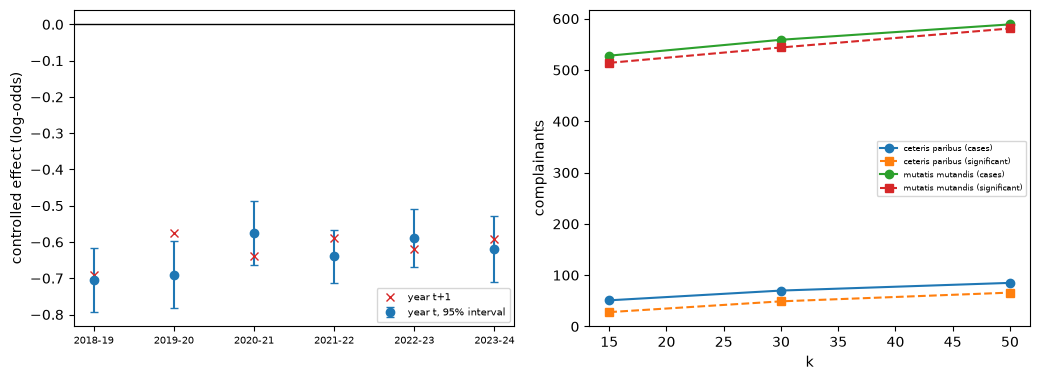

In [9]:
# Left: fit and confirmation effects per year pair; right: cases of the two comparators by neighbourhood size
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.9))
x = np.arange(len(pairs))
left.errorbar(x, [e.coefficient for e in fit_effects], yerr=[[e.coefficient - e.lo for e in fit_effects], [e.hi - e.coefficient for e in fit_effects]], fmt="o", capsize=3, label="year t, 95% interval")
left.plot(x, [e.coefficient for e in confirm_effects], "x", color="tab:red", label="year t+1")
left.axhline(0.0, color="black", linewidth=1)
left.set_xticks(x)
left.set_xticklabels(list(pairs), fontsize=7)
left.set_ylabel("controlled effect (log-odds)")
left.legend(fontsize=7)
labels = ["ceteris paribus", "mutatis mutandis"]
for j, label in enumerate(labels):
    right.plot((15, 30, 50), [counts[(k, label)].n_cases for k in (15, 30, 50)], "o-", label=label + " (cases)")
    right.plot((15, 30, 50), [counts[(k, label)].n_significant for k in (15, 30, 50)], "s--", label=label + " (significant)")
right.set_xlabel("k")
right.set_ylabel("complainants")
right.legend(fontsize=6)
fig.tight_layout()
plt.show()

## Results

- **An omitted proxy creates an effect, and a control removes it.** On the proxy plant the decision never reads the protected indicator, yet the decision model with the covariates only finds a protected effect of +1.2710 (odds ratio 3.5643, 95% interval from +1.2053 to +1.3366). With the proxy among the controls the effect is -0.0341 (odds ratio 0.9665, interval from -0.1253 to +0.0570), which contains the true value 0. The sign of the first effect is the plant's (the proxy raises approval); the lesson is that a controlled effect measures what the controls leave out. For HMDA the control the data withhold is the credit score.
- **The rate-spread model recovers a known effect and tells what it dropped.** From 6,000 loans with 20% of the spreads missing it uses 4,788 rows and drops 1,212, never imputing them, and estimates +0.4195 percentage points (interval from +0.3909 to +0.4482) for a true +0.4000.
- **The controlled disparity of Delaware repeats every year.** For the Black against the White group the controlled effect is negative in all six year pairs, from -0.7049 (odds ratio 0.4941) in 2018 to -0.5911 in 2024, with the same sign in each confirmation year and size ratios between 0.8314 and 1.1143. The engine's replication light is green in all six and equals the committed row. The controls are the nine the document lists (debt-to-income, combined loan-to-value, income, loan amount, property value, loan type, loan purpose, lien status, occupancy type), and `credit_score` is listed as missing. Replication is a statement about the estimate: it does not say what the missing control would change.
- **The situation test sees what the ceteris-paribus comparator cannot.** In the structural data the decision never reads the protected attribute: the protected applicants are approved at 0.3792 against 0.5999 because of the mediators. For one complainant (denied, and approved under its counterfactual) the ceteris-paribus comparator finds the test group denied as well (Δp = 0), while the mutatis-mutandis comparator, whose test group is built around the counterfactual, finds Δp = +1.0000, significant. Over the 2,268 protected applicants at k = 30, the ceteris-paribus test finds 70 potential cases and 49 significant (a share of 0.0216, green), and the mutatis-mutandis test 559 and 544 (a share of 0.2399, amber). The counts grow with k in both. The comparator is the finding: comparing like with like (in the observed profile) hides a disparity that sits in the mediators.
- **The committed HMDA situation test is ceteris paribus only.** It tested the 4,485 race-protected applicants of 2018 at k = 30 and found 3,286 potential cases and 1,179 significant, a share of 0.2629 (amber, and the engine rebuilt from the counts gives the same light). The mutatis-mutandis comparator was not run, because public HMDA gives no counterfactual data. The ceteris-paribus share is not comparable with the structural data's: here the applicants are real and the unobserved credit score is part of the difference.

What the results do not show: none of these tests identifies a cause or a violation. The Interagency Procedures describe statistical analysis as a way to assist an evaluation and do not take a gross disparity as proof; the 2026 amendment of Regulation B says the effects test does not apply under the ECOA, and the Fair Housing Act is a separate statute. The structural data are synthetic with our seed (the paper's own file is not redistributed and its published counts are not reproduced here); the amber cut point 0.20 is a convention set on a measured size and power.

## Summary

- A controlled disparity is the protected effect of a logistic decision model (or of a linear rate-spread model) given the permitted controls; it is an approximation of comparative evidence, an omitted proxy creates an effect, and a missing control (the credit score in public HMDA) is the caller's statement.
- The rate-spread model drops the rows with no spread and never imputes them.
- Replication compares the sign and the size of the effect fitted on year $t$ with the refit on year $t+1$; the Black against White controlled effect of Delaware keeps its sign in all six year pairs, with the engine reproducing every committed light.
- Situation testing compares each complainant with the $k$ nearest protected applicants and with the $k$ nearest others (or those nearest the counterfactual); on data with a known structure the mutatis-mutandis comparator finds the disparity that sits in the mediators and the ceteris-paribus one does not.
- The committed HMDA situation test is ceteris paribus only, because public HMDA has no counterfactual data; none of these tests decides discrimination.

**What to try next.** Notebook 08 places these tests among the toolkits and libraries that exist, and compares two of the engine's functions with independent references.

## References

- OCC, FDIC, Federal Reserve Board, OTS and NCUA (2009), Interagency Fair Lending Examination Procedures. https://www.federalreserve.gov/boarddocs/caletters/2009/0906/09-06_attachment.pdf
- CFPB (2026), Equal Credit Opportunity Act (Regulation B), final rule, 91 FR 21620, effective 2026-07-21. https://www.govinfo.gov/content/pkg/FR-2026-04-22/pdf/2026-07804.pdf
- Alvarez, J. M. and Ruggieri, S. (2025), Counterfactual situation testing: from single to multidimensional discrimination, Journal of Artificial Intelligence Research 82, arXiv 2502.01267. https://doi.org/10.1613/jair.1.17935
- Alvarez, J. M. and Ruggieri, S. (2026), Mutatis mutandis: revisiting the comparator in discrimination testing, Computational Intelligence 42(4), arXiv 2405.13693. https://doi.org/10.1111/coin.70238
- FFIEC and CFPB, Home Mortgage Disclosure Act data publication (the licence sentence of the data is UNVERIFIED). https://ffiec.cfpb.gov/data-publication/
- Kozodoi, N., Jacob, J. and Lessmann, S. (2022), Fairness in credit scoring: assessment, implementation and profit implications, European Journal of Operational Research 297(3). https://doi.org/10.1016/j.ejor.2021.06.023